# Candidate-Goal Graph Routing for Atlas-DeePC

This experiment compares baseline Atlas-DeePC with a terminal-configuration selector based on graph path cost. Both use the same frozen 48-chart physical atlas, cached rank-60 behavioral matrices, offline random-walk library, DeePC QP, input limits, 7 cm target-reference latch, 320 control steps, and strict success metric. There is no contextual atlas or contextual rescue.

The paired evaluation panel is **500 seeds, 211–710**. These seeds have appeared in prior experiments; this is a paired ablation, not a new untouched evaluation. Results appear after running the experiment cell. Existing results from other timing settings are not silently reused.

In [1]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/atlas_deepc_mpl")
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[variable] = "1"

import sys
import json
import math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src" / "candidate_goal_routing_experiment.py").exists()), None)
assert ROOT is not None, "Open this notebook from the atlas_deepc_reacher project"
sys.path.insert(0, str(ROOT / "src"))
import routed_deepc_experiment as baseline
import candidate_goal_routing_experiment as experiment

SEEDS = list(range(211, 711))  # Change this range to evaluate other seeds.
CANDIDATE_COUNTS = [10, 50, 100, 200, 400]
RUN_EXPERIMENTS = True
OVERWRITE = False  # True reruns all methods for fresh local timing.
DATA_PATH = ROOT / "data/select_iid_offline_hankel.npy"
RESULT_ROOT = ROOT / "experiments/routed_deepc_iid"
ATLAS_PATH = RESULT_ROOT / "clustering_jointconfig48_fresh211_310/behavioral_atlas.npz"
BASELINE_SUMMARY = RESULT_ROOT / "clustering_jointconfig48_baseline_cache/summary.json"
OUTPUT_DIR = RESULT_ROOT / "candidate_goal_routing_500"

source = json.loads(BASELINE_SUMMARY.read_text())
config = baseline.RoutedDeePCConfig(**source["config"])
assert config.clusters == 48 and config.svd_rank == 60
assert config.clustering_feature_mode == "plant_joint_configuration"
assert config.target_matrix_mode == "current" and config.formulation == "svd_current"
assert config.steps == 320
assert set(SEEDS).issubset({int(r["seed"]) for r in source["results"]}) or SEEDS != list(range(211, 711))
print(f"{len(SEEDS)} seeds: {SEEDS[0]}–{SEEDS[-1]}")
print("Candidate counts:", CANDIDATE_COUNTS)
display(pd.Series(vars(config), name="Shared controller settings"))

500 seeds: 211–710
Candidate counts: [10, 50, 100, 200, 400]


clusters                                                  48
cluster_seed                                              11
clustering_input_weight                                  0.0
clustering_method                           minibatch_kmeans
clustering_feature_mode            plant_joint_configuration
clustering_subspace_rank                                   6
clustering_max_iter                                       20
clustering_configuration_weight                          1.0
clustering_velocity_weight                               1.0
clustering_fingertip_weight                              1.0
formulation                                      svd_current
overlap_charts                                             2
svd_rank                                                  60
svd_bound_scale                                          3.0
negative_mass                                            0.2
edge_count_threshold                                       3
target_switch_distance  

## 1. Goal candidates and repeated route selection

For target $p^*=(p_x,p_y)$, take the top-$N$ eligible offline configurations ranked by $\|p_i-p^*\|_2$. Eligibility uses the same baseline fairness rule: the source episode's own target must be at least 6 cm from the online target. This does not exclude offline fingertip positions near the online target.

The configuration for a Hankel column is taken at the **last sample of $Y_p$**, matching the state used to fit its physical chart label. The old baseline goal helper uses the first output sample; the unchanged baseline retains that convention. The candidate method aligns the candidate state with the stored label instead of introducing this temporal mismatch.

Let $\ell_i$ be each candidate's physical chart. The graph retains exactly the baseline directed edges and costs:

$$w_{ab}=\frac{\|\mu_a-\mu_b\|_2/\sqrt{d}}{\sqrt{n_{ab}}},\qquad n_{ab}\geq3.$$

Here $\mu$ denotes the standardized atlas feature center, $d$ its dimension, and $n_{ab}$ the observed offline transition count. At every step, localize the measured current chart $k_t$, then choose

$$i_t^*=\arg\min_{i\in\mathcal I_N(p^*)}D(k_t,\ell_i),$$

where $D$ is the sum of edge costs along a shortest directed path. Ties are broken by fingertip error, then offline sample index. Thus candidates in the same chart need only one comparison. Unreachable candidates have infinite cost; if all are unreachable, the experiment stops with an explicit error.

Copy the selected candidate's configuration channels, set its velocities to zero, and set its fingertip channels to the exact online target. This gives the full terminal reference. The reference has the baseline's approximate consistency: copied joint channels come from a nearby sampled position, while its position channels use the exact target. The candidate mismatch is reported below.

DeePC receives **only the cached full input-output basis of the current chart**. Before target-reference handoff it tracks the next route chart's medoid; after handoff it tracks the newly selected full terminal reference. The existing 7 cm latch selects which type of reference to use; it does **not freeze the selected candidate**. Candidate selection continues at every step, including near the target. No new dwell trigger, branch lock, or early termination is added.

## 2. Timing protocol

The graph is fixed, so all-pairs shortest paths are cached once, before any rollout. Online rerouting remains responsive to the measured current chart: it compares cached distances to candidate charts, chooses a goal, and reconstructs the selected route. It does not repeat a graph search unnecessarily.

We report separately:

- Shared offline SVD, graph-table preparation, and source-episode metadata loading. Source metadata is warmed once for both methods before rollout timing.
- Per-rollout goal setup: baseline branch construction, or candidate lookup and grouping.
- Per-step current-chart localization, goal selection, route reconstruction, matrix lookup, and DeePC QP solve.
- Other loop overhead, total computation, and goal setup amortized across the rollout.

Runs are sequential with one numerical-library thread. Method order rotates across seeds. Solver timing wraps the same `DeePCController.solve` call for every method, including its problem preparation. Environment stepping and file saving are outside control timing. Resume skips completed checkpoints in this experiment directory; use a new output directory or `OVERWRITE=True` for fresh machine timing.

The baseline uses its original Dijkstra routing implementation. Therefore routing-time savings combine cached shortest paths with the new goal-selection rule; they do not isolate an intrinsic speed advantage of the rule alone. The unchanged QP may dominate total time. Neither speedup nor success improvement is assumed.

In [2]:
if RUN_EXPERIMENTS:
    payload = experiment.run_panel(
        SEEDS, CANDIDATE_COUNTS, config, DATA_PATH, ATLAS_PATH, OUTPUT_DIR,
        overwrite=OVERWRITE, progress_every=10,
    )
else:
    payload = json.loads((OUTPUT_DIR / "summary.json").read_text())

METHODS = ["Baseline Atlas"] + [f"Candidate N={n}" for n in CANDIDATE_COUNTS]
rows = [r for r in payload["results"] if r["seed"] in SEEDS and r["method"] in METHODS]
frame = pd.DataFrame(rows)
assert not frame.duplicated(["method", "seed"]).any()
for method in METHODS:
    found = set(frame.loc[frame.method == method, "seed"])
    assert found == set(SEEDS), f"Incomplete panel: {method}, missing {sorted(set(SEEDS) - found)}"
frame["strict_success"] = frame.apply(experiment.strict_success, axis=1)
frame["amortized_control_ms"] = frame.mean_control_compute_time_ms + frame.goal_setup_time_ms / config.steps
display(pd.Series({k: v for k, v in payload["manifest"].items() if k.endswith("_s")}, name="Offline seconds"))

10/3000: seed 212, Candidate N=200, strict=False, tail100=10.254 mm


20/3000: seed 214, Candidate N=200, strict=True, tail100=2.150 mm


30/3000: seed 215, Candidate N=100, strict=True, tail100=0.950 mm


40/3000: seed 217, Candidate N=100, strict=True, tail100=3.324 mm


50/3000: seed 219, Candidate N=100, strict=True, tail100=1.646 mm


60/3000: seed 220, Candidate N=50, strict=True, tail100=1.276 mm


... (291 outputs left out)

2980/3000: seed 707, Candidate N=10, strict=True, tail100=3.596 mm


2990/3000: seed 709, Candidate N=10, strict=True, tail100=1.316 mm


3000/3000: seed 710, Baseline Atlas, strict=True, tail100=1.583 mm


shared_offline_preparation_s    0.734286
shared_chart_svd_s              0.130807
shared_all_pairs_routing_s      0.002876
shared_source_metadata_s        0.593208
Name: Offline seconds, dtype: float64

## 3. Paired success comparison

In [3]:
def wilson(successes, total):
    z = 1.959963984540054
    p = successes / total
    center = (p + z*z/(2*total)) / (1 + z*z/total)
    half = z * np.sqrt(p*(1-p)/total + z*z/(4*total*total)) / (1 + z*z/total)
    return center-half, center+half

summary_rows = []
for method in METHODS:
    group = frame[frame.method == method]
    successes = int(group.strict_success.sum())
    lo, hi = wilson(successes, len(group))
    summary_rows.append({
        "method": method, "successes": successes, "rollouts": len(group),
        "success_pct": 100*successes/len(group), "CI_low_pct": 100*lo, "CI_high_pct": 100*hi,
        "median_tail100_mm": 1000*group.mean_last_100.median(),
        "mean_step_ms": group.mean_control_compute_time_ms.mean(),
        "median_rollout_median_step_ms": group.median_control_compute_time_ms.median(),
        "mean_amortized_step_ms": group.amortized_control_ms.mean(),
        "mean_goal_setup_ms": group.goal_setup_time_ms.mean(),
    })
summary = pd.DataFrame(summary_rows).set_index("method").loc[METHODS]
display(summary.round(3))

success = frame.pivot(index="seed", columns="method", values="strict_success").loc[SEEDS]
paired = []
for method in METHODS[1:]:
    repaired = success.index[~success["Baseline Atlas"] & success[method]].tolist()
    regressed = success.index[success["Baseline Atlas"] & ~success[method]].tolist()
    a, b = len(repaired), len(regressed)
    n = a+b
    p = 1.0 if n == 0 else min(1.0, 2*sum(math.comb(n, j) for j in range(min(a,b)+1)) / 2**n)
    paired.append({"method": method, "repaired": a, "regressed": b, "net": a-b,
                   "McNemar_p_unadjusted": p, "repaired_seeds": repaired, "regressed_seeds": regressed})
display(pd.DataFrame(paired).set_index("method"))

,successes,rollouts,success_pct,CI_low_pct,CI_high_pct,median_tail100_mm,mean_step_ms,median_rollout_median_step_ms,mean_amortized_step_ms,mean_goal_setup_ms
method,,,,,,,,,,
Baseline Atlas,443,500,88.6,85.515,91.096,2.161,37.621,35.001,37.643,7.029
Candidate N=10,450,500,90.0,87.058,92.332,2.111,37.613,35.094,37.631,5.748
Candidate N=50,448,500,89.6,86.616,91.981,2.463,37.555,34.981,37.573,5.546
Candidate N=100,426,500,85.2,81.819,88.044,2.666,37.534,34.946,37.551,5.544
Candidate N=200,391,500,78.2,74.373,81.597,3.005,37.408,34.892,37.425,5.582
Candidate N=400,354,500,70.8,66.668,74.615,3.481,37.410,34.926,37.427,5.543


,repaired,regressed,net,McNemar_p_unadjusted,repaired_seeds,regressed_seeds
method,,,,,,
Candidate N=10,17,10,7,2.477886e-01,"[277, 283, 344, 349, 396, 406, 449, 478, 508, ...","[231, 318, 336, 387, 427, 450, 495, 527, 577, ..."
Candidate N=50,19,14,5,4.868502e-01,"[254, 277, 283, 344, 349, 396, 406, 449, 478, ...","[318, 320, 336, 361, 387, 427, 431, 450, 476, ..."
Candidate N=100,21,38,-17,3.634318e-02,"[254, 277, 283, 299, 344, 349, 396, 405, 406, ...","[212, 291, 295, 318, 320, 336, 340, 361, 368, ..."
Candidate N=200,13,65,-52,1.807703e-09,"[254, 283, 299, 344, 349, 396, 405, 449, 508, ...","[212, 235, 239, 240, 257, 260, 278, 289, 291, ..."
Candidate N=400,11,100,-89,4.085373e-19,"[254, 283, 299, 349, 396, 405, 429, 508, 541, ...","[212, 213, 215, 225, 235, 239, 240, 257, 260, ..."


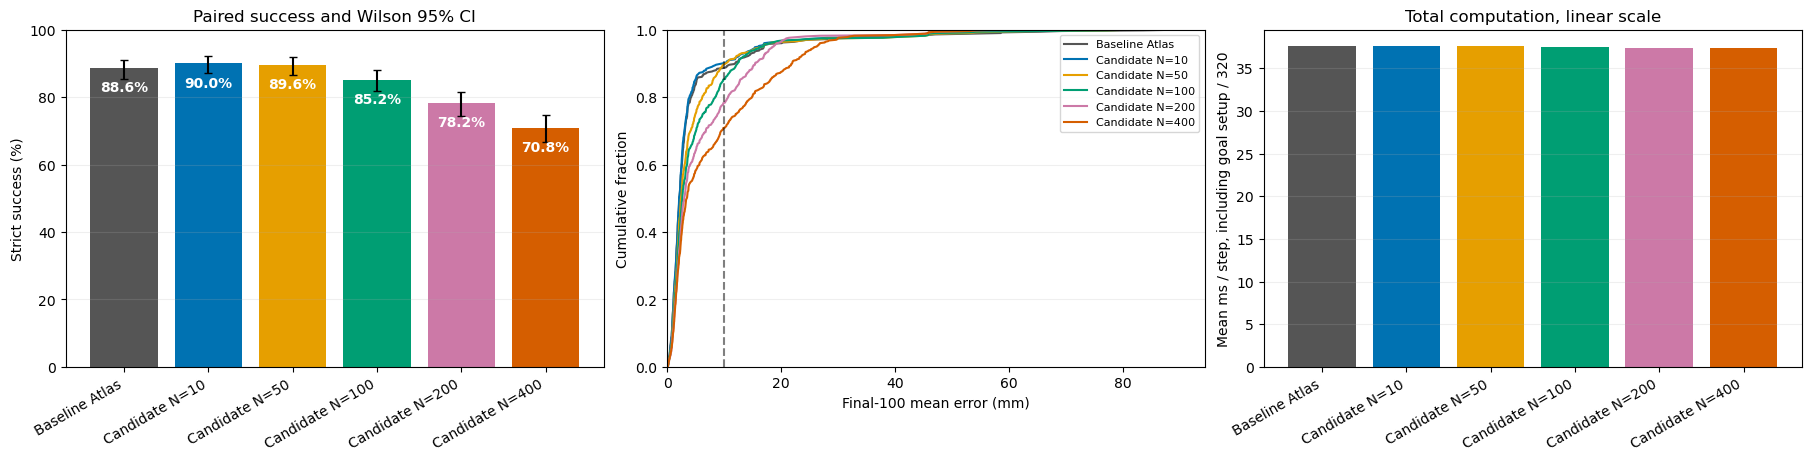

In [4]:
colors = ["#555555", "#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00"]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), constrained_layout=True)
x = np.arange(len(METHODS))
axes[0].bar(x, summary.success_pct, color=[colors[i % len(colors)] for i in x])
axes[0].errorbar(x, summary.success_pct,
                yerr=np.vstack([summary.success_pct-summary.CI_low_pct, summary.CI_high_pct-summary.success_pct]),
                fmt="none", color="black", capsize=3)
axes[0].set(ylim=(0, 100), ylabel="Strict success (%)", title="Paired success and Wilson 95% CI")
for i, value in enumerate(summary.success_pct):
    axes[0].text(i, max(1, value-7), f"{value:.1f}%", ha="center", color="white", weight="bold")
for i, method in enumerate(METHODS):
    error = np.sort(1000*frame.loc[frame.method == method, "mean_last_100"])
    axes[1].plot(error, np.arange(1,len(error)+1)/len(error), label=method, color=colors[i % len(colors)])
axes[1].axvline(10, color="black", linestyle="--", alpha=.5)
axes[1].set(xlabel="Final-100 mean error (mm)", ylabel="Cumulative fraction", xlim=(0,None), ylim=(0,1))
axes[1].legend(fontsize=8)
axes[2].bar(x, summary.mean_amortized_step_ms, color=[colors[i % len(colors)] for i in x])
axes[2].set(ylabel="Mean ms / step, including goal setup / 320", ylim=(0,None), title="Total computation, linear scale")
for ax in (axes[0], axes[2]):
    ax.set_xticks(x, METHODS, rotation=30, ha="right")
for ax in axes:
    ax.grid(axis="y", alpha=.2)
fig.savefig(OUTPUT_DIR / "success_and_runtime.png", dpi=170)
plt.show()

## 4. Computational time by module

Stacked components are **means of per-rollout means**, with equal weight for every seed. They sum to the mean total control time; stacking separate medians would not preserve that identity. The separate median and p95 tables describe variation without treating medians as additive.

,Current-chart localization,Candidate goal selection,Route search / reconstruction,Behavioral matrix lookup,DeePC solve call,Other control overhead
method,,,,,,
Baseline Atlas,0.0770,0.0000,0.0219,0.0008,37.4741,0.0469
Candidate N=10,0.0768,0.0167,0.0068,0.0008,37.4720,0.0401
Candidate N=50,0.0768,0.0165,0.0067,0.0008,37.4147,0.0396
Candidate N=100,0.0769,0.0165,0.0067,0.0008,37.3934,0.0398
Candidate N=200,0.0766,0.0165,0.0067,0.0008,37.2674,0.0395
Candidate N=400,0.0768,0.0166,0.0067,0.0008,37.2691,0.0400


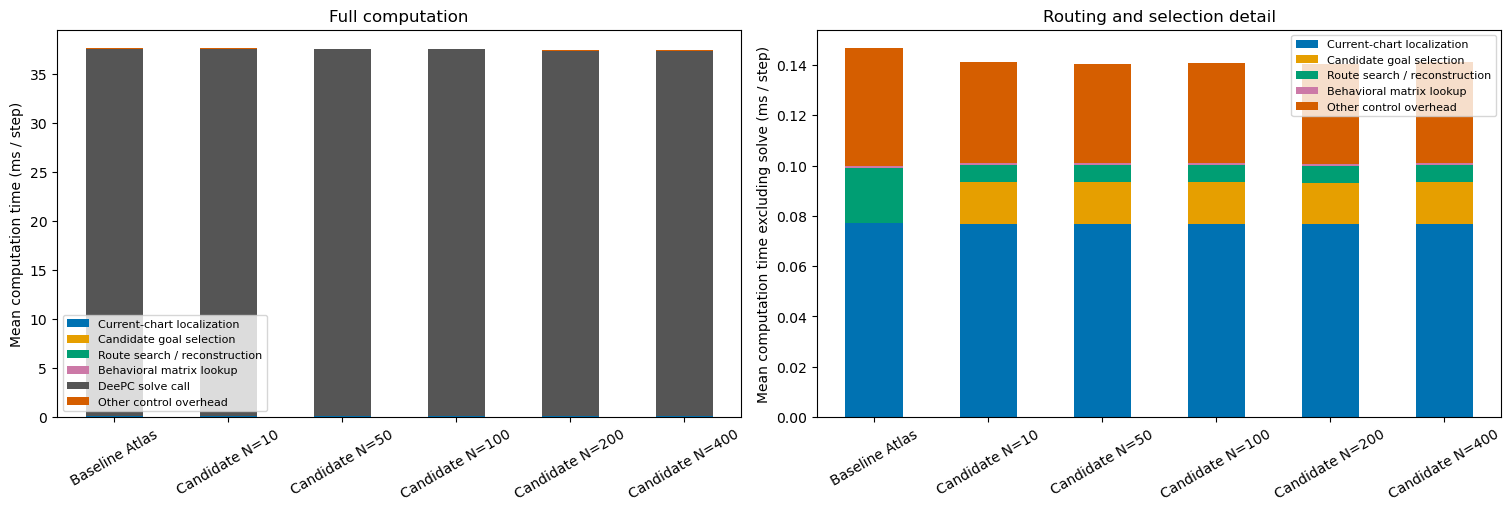

,p95_localization_time_ms,p95_goal_selection_time_ms,p95_routing_time_ms,p95_matrix_preparation_time_ms,p95_solve_time_ms,p95_control_compute_time_ms
Mean of per-rollout p95 times,,,,,,
Baseline Atlas,0.1079,0.0000,0.0521,0.0011,44.3234,44.5147
Candidate N=10,0.1096,0.0233,0.0089,0.0010,44.1821,44.3514
Candidate N=50,0.1090,0.0227,0.0088,0.0010,44.1994,44.3822
Candidate N=100,0.1086,0.0231,0.0088,0.0010,44.1576,44.3285
Candidate N=200,0.1082,0.0229,0.0088,0.0010,43.8693,44.0371
Candidate N=400,0.1079,0.0228,0.0088,0.0010,43.8287,44.0016


,mean_goal_setup_ms,mean_step_ms,mean_amortized_step_ms
method,,,
Baseline Atlas,7.0293,37.6208,37.6428
Candidate N=10,5.7476,37.6131,37.6311
Candidate N=50,5.5456,37.5552,37.5725
Candidate N=100,5.5438,37.5342,37.5515
Candidate N=200,5.5816,37.4076,37.4251
Candidate N=400,5.5426,37.4101,37.4275


In [5]:
components = {
    "mean_localization_time_ms": "Current-chart localization",
    "mean_goal_selection_time_ms": "Candidate goal selection",
    "mean_routing_time_ms": "Route search / reconstruction",
    "mean_matrix_preparation_time_ms": "Behavioral matrix lookup",
    "mean_solve_time_ms": "DeePC solve call",
    "mean_other_time_ms": "Other control overhead",
}
times = frame.groupby("method")[list(components)].mean().reindex(METHODS)
display(times.rename(columns=components).round(4))
assert np.allclose(times.sum(axis=1), summary.mean_step_ms)
fig, axes = plt.subplots(1, 2, figsize=(15,5), constrained_layout=True)
times.rename(columns=components).plot.bar(stacked=True, ax=axes[0], color=["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#555555", "#D55E00"])
axes[0].set(ylabel="Mean computation time (ms / step)", ylim=(0,None), xlabel="", title="Full computation")
small = times.drop(columns="mean_solve_time_ms")
small.rename(columns=components).plot.bar(stacked=True, ax=axes[1], color=["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00"])
axes[1].set(ylabel="Mean computation time excluding solve (ms / step)", ylim=(0,None), xlabel="", title="Routing and selection detail")
for ax in axes:
    ax.tick_params(axis="x", labelrotation=30)
    ax.legend(fontsize=8)
fig.savefig(OUTPUT_DIR / "module_runtime.png", dpi=170)
plt.show()
p95_columns = [f"p95_{key[:-1]}ms" for key in experiment.TIMING_KEYS]
display(frame.groupby("method")[p95_columns].mean().reindex(METHODS).round(4).rename_axis("Mean of per-rollout p95 times"))
display(summary[["mean_goal_setup_ms", "mean_step_ms", "mean_amortized_step_ms"]].round(4))

## 5. Candidate coverage and reference switching

Increasing $N$ can offer more reachable goal charts, but can also admit configurations farther from the target. A candidate in the current chart has zero graph path cost even if its posture is not the easiest physical target. Edge costs are empirical graph costs, not certificates of joint-limit feasibility or control effort.

The switching diagnostics test the consequence of recomputing the terminal configuration at every step, including after first entering the 1 cm region. This experiment does not hide later drift by stopping early.

,goal_sample_switches,goal_chart_switches,goal_switches_after_first_reach,candidate_unique_charts,candidate_max_xy_error_mm
method,,,,,
Baseline Atlas,0.000,0.000,0.000,NaN,NaN
Candidate N=10,0.604,0.604,0.600,2.178,4.382
Candidate N=50,1.468,1.468,1.420,2.838,9.840
Candidate N=100,1.614,1.614,1.450,3.344,13.785
Candidate N=200,2.216,2.216,1.406,4.058,19.292
Candidate N=400,2.934,2.934,1.400,5.002,27.014


Offline target-separation check passed for every selected goal, including later reselections.
The target-conditioned candidate lookup occurs once per rollout; online comparisons use candidate chart IDs.


,method,strict_success,mean_last_30,mean_last_100,goal_sample_switches,goal_chart_switches
396,Baseline Atlas,False,0.058574,0.058574,0,0
397,Candidate N=10,True,0.001352,0.001352,0,0
398,Candidate N=50,True,0.001352,0.001352,0,0
399,Candidate N=100,True,0.001352,0.001352,0,0
400,Candidate N=200,False,0.010394,0.010394,0,0
401,Candidate N=400,False,0.010394,0.010394,0,0


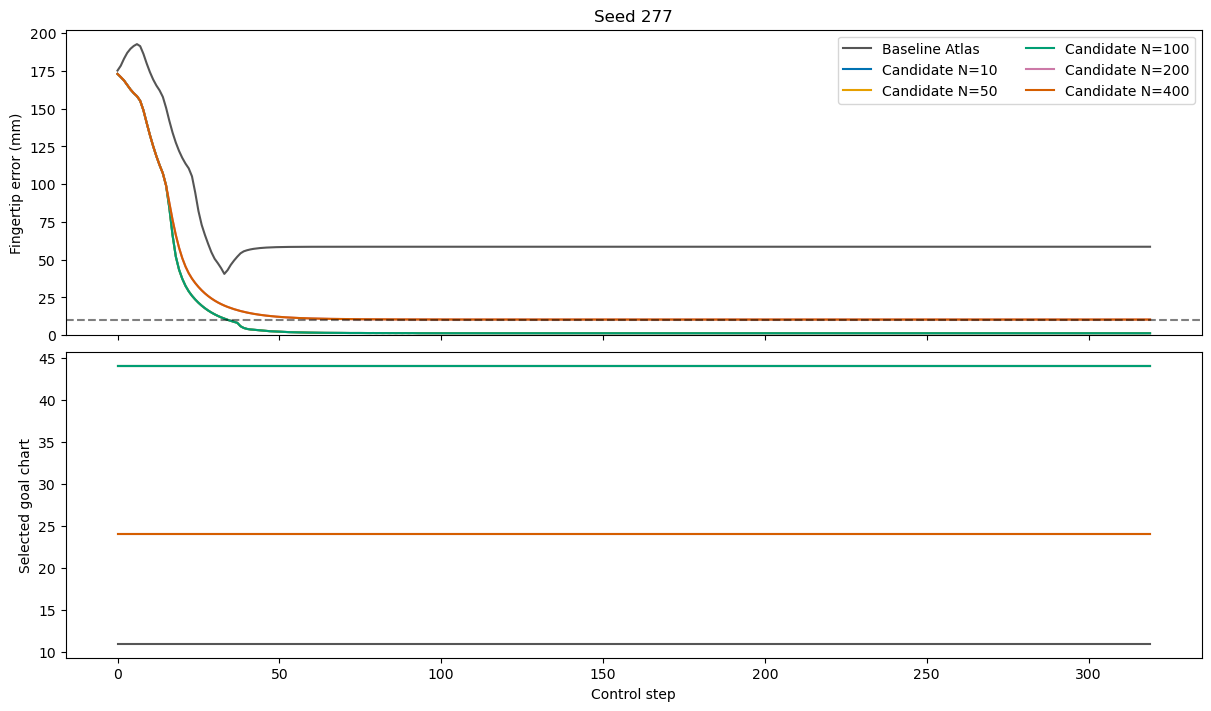

In [6]:
diagnostics = ["goal_sample_switches", "goal_chart_switches", "goal_switches_after_first_reach",
               "candidate_unique_charts", "candidate_max_xy_error_mm"]
display(frame.groupby("method")[diagnostics].mean().reindex(METHODS).round(3))
assert (frame.minimum_selected_goal_source_separation >= config.goal_source_target_min_distance - 1e-12).all()
assert not frame.fitted_dynamics_model.any()
assert not frame.online_nearest_trajectory_retrieval.any()
print("Offline target-separation check passed for every selected goal, including later reselections.")
print("The target-conditioned candidate lookup occurs once per rollout; online comparisons use candidate chart IDs.")

FAILURE_SEED = 277
if FAILURE_SEED in SEEDS:
    display(frame.loc[frame.seed == FAILURE_SEED, ["method", "strict_success", "mean_last_30", "mean_last_100",
                                                    "goal_sample_switches", "goal_chart_switches"]])
    fig, axes = plt.subplots(2,1, figsize=(12,7), sharex=True, constrained_layout=True)
    for i, (method, n) in enumerate([(METHODS[0], None)] + [(f"Candidate N={n}", n) for n in CANDIDATE_COUNTS]):
        folder = "baseline" if n is None else f"candidate_{n}"
        with np.load(OUTPUT_DIR / folder / f"seed{FAILURE_SEED}.npz") as trace:
            axes[0].plot(1000*trace["distance"], label=method, color=colors[i % len(colors)])
            axes[1].step(np.arange(config.steps), trace["goal_chart"], where="post", label=method, color=colors[i % len(colors)])
    axes[0].axhline(10, color="black", linestyle="--", alpha=.5)
    axes[0].set(ylabel="Fingertip error (mm)", title=f"Seed {FAILURE_SEED}", ylim=(0,None))
    axes[0].legend(ncol=2)
    axes[1].set(xlabel="Control step", ylabel="Selected goal chart")
    plt.show()

## 6. Implementation validation

Before the 500-seed sweep, a full 320-step paired check was run on the previously failing **seed 277**. Baseline final-100 mean fingertip error was **58.574 mm**; candidate routing with **N=400** gave **10.394 mm**. Both failed the unchanged strict success criterion. This is a single-seed implementation check, not an estimate of success rate or speedup. The baseline error reproduced its saved original result to numerical precision.

Focused tests also verify cached paths against the baseline Dijkstra implementation, top-N configuration selection at the correct Hankel time index, deterministic within-chart tie breaking, and goal reselection as the current chart changes. Every analysis and plotting cell was checked against the small paired result set. The full 500-seed results are computed by Section 2's experiment cell.